# Base GBA model as a COBRAk model

Builds the 8-reaction base model of the manuscript (TS, ATPS, AAS, NTS, ADPS, RNAP, DNAP, R) as a COBRAk `Model` from scratch, and runs two checks: an enzyme-constrained LP (kcat and MW only) and the kinetic NLP (Km and activation constants, no dG0).

**Where each input comes from**

| Input | Source in the manuscript |
|---|---|
| Reaction stoichiometries (molar) | SI, "Construction of the mass fraction matrix", with the molar masses of Table S (masses) |
| Biomass reaction | Methods, "Parameters and experimental data" (composition after rescaling) |
| kcat | Methods, Table of turnover numbers (g product / (g protein h)) |
| Km, activation constants | Methods, Table of K values (g/L) and the text on activation constants |

**Units in the COBRAk model.** Fluxes in mmol/gDW/h, metabolite concentrations in mol/L, enzyme concentrations in mmol/gDW, molecular weights in kDa, kcat in 1/h, protein pool in g/gDW. The manuscript works in mass units, so every mass-based number is converted (see the conversion cell).

**Choices that the manuscript does not fix** (all are set in the config cell):

1. `M_S`: molar mass of the lumped species S (and of the external carbon source). Only sets the unit of S. Results do not depend on it.
2. `ENZ_MW_KDA`: molecular weight of each enzyme (kDa). The mass kcat is converted to the molar kcat with these values, so growth rates and proteome fractions do not depend on them. They only change the enzyme concentrations (mmol/gDW) and the molar kcat values.
3. `CONC_FACTOR`: how far metabolite concentrations may move from their reference values (see config cell).

## 1. Imports and configuration

In [1]:
import os
import sys
from math import log

from cobrak.dataclasses import (
    Enzyme,
    EnzymeReactionData,
    HillCoefficients,
    Metabolite,
    Model,
    Reaction,
    Solver,
)
from cobrak.io import json_write
from cobrak.lps import perform_lp_optimization
from cobrak.nlps import perform_nlp_irreversible_optimization
from cobrak.standard_solvers import CPLEX

os.environ["PATH"] = "/home/users/dszeliova/.conda/envs/optenz/bin:" + os.environ["PATH"]
IPOPT = Solver(
    name="ipopt",
)

OUTPUT_JSON = "base_model_cobrak.json"

In [2]:
# ---- Free choices (see the first cell) ----
M_S = 180.16          # g/mol, molar mass of S and of the external carbon source Cext
# Molecular weight of each enzyme in kDa (1 kDa = 1000 g/mol)
ENZ_MW_KDA = {
    "TS": 100.0,     # placeholder (not specified)
    "ATPS": 400.0,
    "AAS": 400.0,
    "NTS": 400.0,
    "ADPS": 40.0,
    "RNAP": 480,   # placeholder
    "DNAP": 1000.0,   # placeholder
    "R": 826.0,      # placeholder: protein part of the ribosome, 0.358 x 2,306,967 g/mol
}

# Metabolite concentrations are bounded to [c_ref / CONC_FACTOR, c_ref * CONC_FACTOR],
# with c_ref = rho * biomass fraction (the concentrations used to estimate the Km values).
# 1.0001 = fixed at c_ref. Larger values let the NLP change the concentrations.
CONC_FACTOR = 1.0001

# ---- Values from the manuscript ----
RHO = 186.0           # g/L, effective density used in the simulations without Q sector
A_CEXT = 10.0         # g/L, external carbon source (saturating condition)
A_WEXT = 1e-3         # g/L, external waste. Manuscript gives no value; ~0 = no product inhibition
K_INF = 1e6           # mol/L, Km of products of irreversible reactions (K+ -> infinity)

## 2. Manuscript data

In [3]:
# Molar masses (g/mol), SI Table of masses. Protein and RNA/DNA are per residue.
MW = {
    "Cext": M_S, "S": M_S, "Wext": 44.01,      # Wext = CO2
    "AA": 127.02,   # free amino acid
    "NT": 489.14,   # free nucleotide
    "ATP": 503.15, "ADP": 424.18,
    "P": 109.0,     # amino acid residue in protein
    "RNA": 314.19, "DNA": 314.19,   # nucleotide residue in RNA/DNA
}

# Biomass composition (mass fractions), Methods. S is the remainder.
biomass_fraction = {
    "P": 0.45, "RNA": 0.38, "DNA": 0.05,
    "AA": 0.01, "NT": 0.01, "ATP": 0.01, "ADP": 0.003,
}
biomass_fraction["S"] = 1.0 - sum(biomass_fraction.values())
print("S fraction (remainder):", round(biomass_fraction["S"], 4),
      "-> c_S =", round(RHO * biomass_fraction["S"], 1), "g/L (Km table: 3 x 5.4 = 16.2 g/L)")

# Turnover numbers, g product / (g protein h)
KCAT_MASS = {"TS": 60.2, "ATPS": 1017.1, "AAS": 9.2, "NTS": 685.1,
             "ADPS": 378.7, "RNAP": 20.8, "DNAP": 108.8, "R": 108.4}

# Michaelis constants (g/L): substrates K-, products K+ (reversible kinetics)
K_GL = {
    "TS":   {"Cext": 1.0, "S": 16.2},
    "ATPS": {"S": 5.4, "ADP": 0.2, "ATP": 1.9, "Wext": 1.0},
    "AAS":  {"S": 5.4, "AA": 1.9},
    "NTS":  {"S": 5.4, "ATP": 0.6, "NT": 1.9, "ADP": 0.6},
    "ADPS": {"NT": 0.6, "ADP": 0.6, "S": 16.2},
    "RNAP": {"NT": 0.6},
    "DNAP": {"NT": 0.6},
    "R":    {"AA": 0.6, "ATP": 0.6},
}
IRREVERSIBLE = ["RNAP", "DNAP", "R"]

S fraction (remainder): 0.087 -> c_S = 16.2 g/L (Km table: 3 x 5.4 = 16.2 g/L)


## 3. Stoichiometry from the SI

Each reaction is written with its explicit species (SI). The lumped species S takes up the mass difference between substrates and products, which is the lumping of Glc, O2, Pi, H+, PPi and H2O into S done in the SI. Reactions are written per mole of the reaction as in the SI, for example ATPS for 26 ATP.

In [4]:
def stoichiometry(substrates, products):
    st = {}
    for met, n in substrates.items():
        st[met] = st.get(met, 0.0) - n
    for met, n in products.items():
        st[met] = st.get(met, 0.0) + n
    mass_substrates = sum(n * MW[m] for m, n in substrates.items())
    mass_products = sum(n * MW[m] for m, n in products.items())
    st["S"] = st.get("S", 0.0) + (mass_substrates - mass_products) / M_S
    return st

stoich = {
    "TS":   stoichiometry({"Cext": 1}, {}),                         # Cext -> S
    "ATPS": stoichiometry({"ADP": 26}, {"ATP": 26, "Wext": 6}),     # 26 ATP per glucose
    "AAS":  stoichiometry({}, {"AA": 1}),                           # S -> AA
    "NTS":  stoichiometry({"ATP": 5}, {"NT": 1, "ADP": 5}),         # 5 ATP per nucleotide
    "ADPS": stoichiometry({"NT": 1}, {"ADP": 1}),                   # NT -> ADP + S
    "RNAP": stoichiometry({"NT": 1}, {"RNA": 1}),                   # NT -> RNA + PPi (in S)
    "DNAP": stoichiometry({"NT": 1}, {"DNA": 1}),
    "R":    stoichiometry({"AA": 1, "ATP": 4}, {"P": 1, "ADP": 4}), # 4 ATP per amino acid
}

# Mass of one mole of each reaction (sum of the product masses), g/mol
reaction_mass = {r: sum(v * MW[m] for m, v in st.items() if v > 0) for r, st in stoich.items()}

Check: the molar stoichiometries must give back the mass fraction matrix of Fig. 1.

In [5]:
FIG1_MASS_FRACTIONS = {
    "TS":   {"Cext": -1, "S": 1},
    "ATPS": {"S": -0.17, "ADP": -0.83, "ATP": 0.98, "Wext": 0.02},
    "AAS":  {"S": -1, "AA": 1},
    "NTS":  {"S": -0.04, "ATP": -0.96, "NT": 0.19, "ADP": 0.81},
    "ADPS": {"NT": -1, "ADP": 0.87, "S": 0.13},
    "RNAP": {"NT": -1, "RNA": 0.64, "S": 0.36},
    "DNAP": {"NT": -1, "DNA": 0.64, "S": 0.36},
    "R":    {"AA": -0.06, "ATP": -0.94, "P": 0.05, "ADP": 0.79, "S": 0.16},
}

for r, st in stoich.items():
    derived = {m: v * MW[m] / reaction_mass[r] for m, v in st.items()}
    assert set(derived) == set(FIG1_MASS_FRACTIONS[r]), r
    for m, value in FIG1_MASS_FRACTIONS[r].items():
        assert abs(derived[m] - value) < 0.006, (r, m, derived[m], value)
print("All 8 columns agree with Fig. 1 (to the rounding of the figure).")

All 8 columns agree with Fig. 1 (to the rounding of the figure).


## 4. Unit conversion

* Mass fluxes of GBA are per gram of reaction mass. With the mass of one mole of the reaction `m_l` and the enzyme molecular weight `MW` (kDa = g/mmol):
  `kcat_molar [1/h] = kcat_mass * MW * 1000 / m_l`
* `Km [mol/L] = Km [g/L] / molar mass`, same for the activation constants.
* COBRAk uses the stoichiometric coefficient of a metabolite as the exponent in the saturation term. The convenience kinetics of the manuscript use exponent 1 for every reactant, so the Hill coefficient of each metabolite is set to `1 / |coefficient|`.
* For RNAP, DNAP and R (irreversible in the manuscript) the products get a very large Km (`K_INF`), so the product term vanishes. COBRAk needs at least one product Km to apply the saturation term.

In [6]:
enzymes = {f"E_{r}": Enzyme(molecular_weight=ENZ_MW_KDA[r], name=f"{r} protein") for r in stoich}

reactions = {}
for r, st in stoich.items():
    kcat_molar = KCAT_MASS[r] * ENZ_MW_KDA[r] * 1000.0 / reaction_mass[r]
    k_ms = {m: K_GL[r][m] / MW[m] for m in K_GL[r]}
    if r in IRREVERSIBLE:
        for m, coefficient in st.items():
            if coefficient > 0:
                k_ms[m] = K_INF
    reactions[r] = Reaction(
        stoichiometries=st,
        min_flux=0.0,
        max_flux=1000.0,
        enzyme_reaction_data=EnzymeReactionData(
            identifiers=[f"E_{r}"],
            k_cat=kcat_molar,
            k_ms=k_ms,
            hill_coefficients=HillCoefficients(kappa={m: 1.0 / abs(v) for m, v in st.items()}),
        ),
        name=r,
    )

# Exchange reactions
reactions["EX_Cext"] = Reaction(stoichiometries={"Cext": +1.0}, max_flux=1000.0, name="Carbon source supply")
reactions["EX_Wext"] = Reaction(stoichiometries={"Wext": -1.0}, max_flux=1000.0, name="Waste removal")

# Biomass reaction: mmol of each component per gDW (flux = growth rate in 1/h)
reactions["Biomass"] = Reaction(
    stoichiometries={m: -1000.0 * f / MW[m] for m, f in biomass_fraction.items()},
    max_flux=10.0,
    name="Biomass",
)

# Metabolites with concentration bounds (mol/L, log-transformed)
reference_conc_gl = {m: RHO * f for m, f in biomass_fraction.items()}
reference_conc_gl["Cext"] = A_CEXT
reference_conc_gl["Wext"] = A_WEXT
metabolites = {}
for m in MW:
    c_ref = reference_conc_gl[m] / MW[m]
    metabolites[m] = Metabolite(
        name=m,
        log_min_conc=log(1e-6),
        log_max_conc=log(max(c_ref * CONC_FACTOR, 0.02)),
    )

# Protein pool = modeled proteome = protein fraction of the biomass reaction
model = Model(
    metabolites=metabolites,
    reactions=reactions,
    enzymes=enzymes,
    max_prot_pool=biomass_fraction["P"],
)

## 5. Checks on the built model

In [7]:
# Mass balance of the internal reactions (net mass per mmol must be 0)
for r in stoich:
    net_mass = sum(v * MW[m] for m, v in model.reactions[r].stoichiometries.items())
    print(f"{r:8s} net mass = {net_mass:10.6f} mg/mmol")
    assert abs(net_mass) < 1e-6 * reaction_mass[r], r

# The biomass reaction consumes 1000 mg per gDW
biomass_mass = sum(v * MW[m] for m, v in model.reactions["Biomass"].stoichiometries.items())
print(f"Biomass  net mass = {biomass_mass:10.4f} mg/gDW")
assert abs(biomass_mass + 1000.0) < 1e-6

print()
for r in stoich:
    d = model.reactions[r].enzyme_reaction_data
    print(f"{r:5s} kcat = {d.k_cat:10.1f} 1/h")

TS       net mass =   0.000000 mg/mmol
ATPS     net mass =   0.000000 mg/mmol
AAS      net mass =  -0.000000 mg/mmol
NTS      net mass =   0.000000 mg/mmol
ADPS     net mass =   0.000000 mg/mmol
RNAP     net mass =   0.000000 mg/mmol
DNAP     net mass =   0.000000 mg/mmol
R        net mass =   0.000000 mg/mmol
Biomass  net mass = -1000.0000 mg/gDW

TS    kcat =    33414.7 1/h
ATPS  kcat =    30484.1 1/h
AAS   kcat =    28971.8 1/h
NTS   kcat =   104994.6 1/h
ADPS  kcat =    30968.6 1/h
RNAP  kcat =    20411.3 1/h
DNAP  kcat =   222431.2 1/h
R     kcat =    41847.8 1/h


In [8]:
def reaction_string(reaction, digits=3):
    left = [f"{abs(v):.{digits}g} {m}" for m, v in reaction.stoichiometries.items() if v < 0]
    right = [f"{v:.{digits}g} {m}" for m, v in reaction.stoichiometries.items() if v > 0]
    return " + ".join(left) + " -> " + " + ".join(right)

for r, reaction in model.reactions.items():
    print(f"{r:8s} {reaction_string(reaction)}")

TS       1 Cext -> 1 S
ATPS     26 ADP + 12.9 S -> 26 ATP + 6 Wext
AAS      0.705 S -> 1 AA
NTS      5 ATP + 0.523 S -> 1 NT + 5 ADP
ADPS     1 NT -> 1 ADP + 0.361 S
RNAP     1 NT -> 1 RNA + 0.971 S
DNAP     1 NT -> 1 DNA + 0.971 S
R        1 AA + 4 ATP -> 1 P + 4 ADP + 1.85 S
EX_Cext   -> 1 Cext
EX_Wext  1 Wext -> 
Biomass  4.13 P + 1.21 RNA + 0.159 DNA + 0.0787 AA + 0.0204 NT + 0.0199 ATP + 0.00707 ADP + 0.483 S -> 


## 6. Enzyme-constrained LP (kcat and MW only)

In [9]:
ec_result = perform_lp_optimization(
    model,
    objective_target="Biomass",
    objective_sense=+1,
    with_enzyme_constraints=True,
    solver=CPLEX,
)
print("ecFBA growth rate:", round(ec_result["Biomass"], 4), "1/h")

# Mass balance of the solution (g/gDW/h)
carbon_in = ec_result["EX_Cext"] * M_S / 1000.0
waste_out = ec_result["EX_Wext"] * MW["Wext"] / 1000.0
print(f"carbon in {carbon_in:.3f} = biomass {ec_result['Biomass']:.3f} + waste {waste_out:.3f}")

ecFBA growth rate: 2.1773 1/h
carbon in 2.700 = biomass 2.177 + waste 0.522


## 7. Kinetic NLP (Km and activation constants, no dG0)

`with_gamma=False` because no reaction has a dG0. The saturation term (kappa) uses the Km values, the activation term (alpha) uses the activation constants of RNAP, DNAP and R.

In [10]:
variability_dict = {r: (0.0, reaction.max_flux) for r, reaction in model.reactions.items()}

nlp_result = perform_nlp_irreversible_optimization(
    model,
    objective_target="Biomass",
    objective_sense=+1,
    variability_dict=variability_dict,
    with_kappa=True,
    with_gamma=False,
    with_iota=False,
    with_alpha=False,
    solver=IPOPT,
)
print("NLP growth rate:", round(nlp_result["Biomass"], 4), "1/h")

enzyme_mass = {r: nlp_result[f"enzyme_E_{r}_of_{r}"] * ENZ_MW_KDA[r] for r in stoich}   # g/gDW
total = sum(enzyme_mass.values())
print(f"enzyme pool used: {total:.4f} of {model.max_prot_pool} g/gDW")

NLP growth rate: 1.8393 1/h
enzyme pool used: 0.4500 of 0.45 g/gDW


In [11]:
# Compare with the proteome fractions used to estimate the kcat values (Methods, proteomics table).
# R is compared with the 'P' (translation) row.
paper_fraction = {"TS": 0.065, "ATPS": 0.069, "AAS": 0.248, "NTS": 0.033,
                  "ADPS": 0.001, "RNAP": 0.119, "DNAP": 0.003, "R": 0.462}
print(f"{'enzyme':6s} {'model':>8s} {'proteomics':>11s} {'kappa':>7s}")
for r in stoich:
    kappa = nlp_result.get(f"kappa_var_{r}", float("nan"))
    print(f"{r:6s} {enzyme_mass[r] / total:8.3f} {paper_fraction[r]:11.3f} {kappa:7.3f}")

enzyme    model  proteomics   kappa
TS        0.101       0.065   0.834
ATPS      0.052       0.069   0.933
AAS       0.339       0.248   0.701
NTS       0.026       0.033   0.849
ADPS      0.000       0.001   0.865
RNAP      0.123       0.119   0.942
DNAP      0.003       0.003   0.942
R         0.355       0.462   0.937


## 8. Save the model

In [12]:
json_write(OUTPUT_JSON, model)
print("saved", OUTPUT_JSON)

saved base_model_cobrak.json


## 9. Forced under- and overexpression of each enzyme

For each enzyme the proteome fraction `phi` (its share of the enzyme pool `max_prot_pool`) is fixed to a value between 0 and 1. All other enzymes and all fluxes are free, and the growth rate is maximized. This is done twice:

* **linear**: enzyme-constrained LP (kcat and MW only),
* **nonlinear**: NLP with the saturation term (Km) and the activation term.

At `phi = 0` the reaction cannot carry flux and at `phi = 1` no other enzyme is left. Both reactions are essential, so the growth rate is 0, and these two points are set without solving. Points where IPOPT does not converge are stored as `None` and are left out of the plot.

In [13]:
import json
import logging
from copy import deepcopy

import numpy as np
import matplotlib.pyplot as plt

from cobrak.constants import ALL_OK_KEY

LP_SOLVER = CPLEX
# IPOPT settings are tried in this order until one converges. Different settings fix different points.
NLP_SOLVERS = [
    IPOPT,
    Solver(name="ipopt", solver_options={"nlp_scaling_method": "none", "max_iter": 5000}),
    Solver(name="ipopt", solver_options={"mu_strategy": "adaptive", "max_iter": 5000}),
]

# Pyomo prints a warning for every IPOPT run that does not converge; the failures are counted below instead
logging.getLogger("pyomo.core").setLevel(logging.ERROR)

# Grid of proteome fractions: 0..1 in steps of 0.01, plus a dense log-spaced part at low values
PHI_GRID = np.unique(np.concatenate([np.linspace(0.0, 1.0, 20), np.logspace(-4, -1, 31)]))
PHI_GRID = np.linspace(0.0, 1.0, 21)

SCAN_JSON = "expression_scan_results.json"
FIGURE_FILE = "expression_scan.png"
X_SCALE = "linear"   # "linear" or "symlog" (symlog shows the low-phi region better)

In [14]:
def model_with_forced_enzyme(base_model, reac_id, phi):
    """Copy of the model in which the enzyme of reac_id has the proteome fraction phi."""
    forced_model = deepcopy(base_model)
    enzyme = forced_model.enzymes[f"E_{reac_id}"]
    concentration = phi * forced_model.max_prot_pool / enzyme.molecular_weight   # mmol/gDW
    enzyme.min_conc = concentration
    enzyme.max_conc = concentration
    return forced_model

scan = {r: {"phi": [], "linear": [], "nonlinear": []} for r in stoich}
failed_points = []

for r in stoich:
    print(r)
    for phi in PHI_GRID:
        print(phi)
        phi = float(phi)
        if phi <= 0.0 or phi >= 1.0:
            mu_linear, mu_nonlinear = 0.0, 0.0
        else:
            forced_model = model_with_forced_enzyme(model, r, phi)
            lp_result = perform_lp_optimization(
                forced_model,
                objective_target="Biomass",
                objective_sense=+1,
                with_enzyme_constraints=True,
                solver=LP_SOLVER,
            )
            mu_linear = lp_result["Biomass"]
            mu_nonlinear = None
            for nlp_solver in NLP_SOLVERS:
                try:
                    nlp_scan_result = perform_nlp_irreversible_optimization(
                        forced_model,
                        objective_target="Biomass",
                        objective_sense=+1,
                        variability_dict=variability_dict,
                        with_kappa=True,
                        with_gamma=False,
                        with_iota=False,
                        with_alpha=False,
                        solver=nlp_solver,
                    )
                except Exception:   # IPOPT can stop with an error status far from the optimum
                    continue
                if nlp_scan_result[ALL_OK_KEY]:
                    mu_nonlinear = nlp_scan_result["Biomass"]
                    break
            if mu_nonlinear is None:
                failed_points.append((r, round(phi, 5)))
        scan[r]["phi"].append(phi)
        scan[r]["linear"].append(mu_linear)
        scan[r]["nonlinear"].append(mu_nonlinear)

with open(SCAN_JSON, "w") as f:
    json.dump(scan, f)
print("grid points per enzyme:", len(PHI_GRID))
print("NLP points without a converged solution:", len(failed_points))
if failed_points:
    print(failed_points)

TS
0.0
0.05
0.1
0.15000000000000002
0.2
0.25
0.30000000000000004
0.35000000000000003
0.4
0.45
0.5
0.55
0.6000000000000001
0.65
0.7000000000000001
0.75
0.8
0.8500000000000001
0.9
0.9500000000000001
1.0
ATPS
0.0
0.05
0.1
0.15000000000000002
0.2
0.25
0.30000000000000004
0.35000000000000003
0.4
0.45
0.5
0.55
0.6000000000000001
0.65
0.7000000000000001
0.75
0.8
0.8500000000000001
0.9
0.9500000000000001
1.0
AAS
0.0
0.05
0.1
0.15000000000000002
0.2
0.25
0.30000000000000004
0.35000000000000003
0.4
0.45
0.5
0.55
0.6000000000000001
0.65
0.7000000000000001
0.75
0.8
0.8500000000000001
0.9
0.9500000000000001
1.0
NTS
0.0
0.05
0.1
0.15000000000000002
0.2
0.25
0.30000000000000004
0.35000000000000003
0.4
0.45
0.5
0.55
0.6000000000000001
0.65
0.7000000000000001
0.75
0.8
0.8500000000000001
0.9
0.9500000000000001
1.0
ADPS
0.0
0.05
0.1
0.15000000000000002
0.2
0.25
0.30000000000000004
0.35000000000000003
0.4
0.45
0.5
0.55
0.6000000000000001
0.65
0.7000000000000001
0.75
0.8
0.8500000000000001
0.9
0.9500000000

╭─────────────────────────────── Traceback (most recent call last) ────────────────────────────────╮
│ in <module>:33                                                                                   │
│                                                                                                  │
│   30 │   │   │   mu_nonlinear = None                                                             │
│   31 │   │   │   for nlp_solver in NLP_SOLVERS:                                                  │
│   32 │   │   │   │   try:                                                                        │
│ ❱ 33 │   │   │   │   │   nlp_scan_result = perform_nlp_irreversible_optimization(                │
│   34 │   │   │   │   │   │   forced_model,                                                       │
│   35 │   │   │   │   │   │   objective_target="Biomass",                                         │
│   36 │   │   │   │   │   │   objective_sense=+1,                                                 │
│                                                                                                  │
│ /home/users/dszeliova/.conda/envs/optenz/lib/python3.10/site-packages/pydantic/_internal/_valida │
│ te_call.py:40 in wrapper_function                                                                │
│                                                                                                  │
│    37 │   │                                                                                      │
│    38 │   │   @functools.wraps(wrapped)                                                          │
│    39 │   │   def wrapper_function(*args, **kwargs):                                             │
│ ❱  40 │   │   │   return wrapper(*args, **kwargs)                                                │
│    41 │                                                                                          │
│    42 │   # We need to manually update this because `partial` object has no `__name__` and `__   │
│    43 │   wrapper_function.__name__ = extract_function_name(wrapped)                             │
│                                                                                                  │
│ /home/users/dszeliova/.conda/envs/optenz/lib/python3.10/site-packages/pydantic/_internal/_valida │
│ te_call.py:137 in __call__                                                                       │
│                                                                                                  │
│   134 │   │   if not self.__pydantic_complete__:                                                 │
│   135 │   │   │   self._create_validators()                                                      │
│   136 │   │                                                                                      │
│ ❱ 137 │   │   res = self.__pydantic_validator__.validate_python(pydantic_core.ArgsKwargs(args,   │
│   138 │   │   if self.__return_pydantic_validator__:                                             │
│   139 │   │   │   return self.__return_pydantic_validator__(res)                                 │
│   140 │   │   else:                                                                              │
│                                                                                                  │
│ /home/users/dszeliova/.conda/envs/optenz/lib/python3.10/site-packages/cobrak/nlps.py:884 in      │
│ perform_nlp_irreversible_optimization                                                            │
│                                                                                                  │
│    881 │   )                                                                                     │
│    882 │   nlp_model.obj = get_objective(nlp_model, objective_target, objective_sense)           │
│    883 │   pyomo_solver = get_solver(solver)                                                     │
│ ❱  884 │   results = pyomo_solver.solve(nlp_model, tee=verb

### Plot

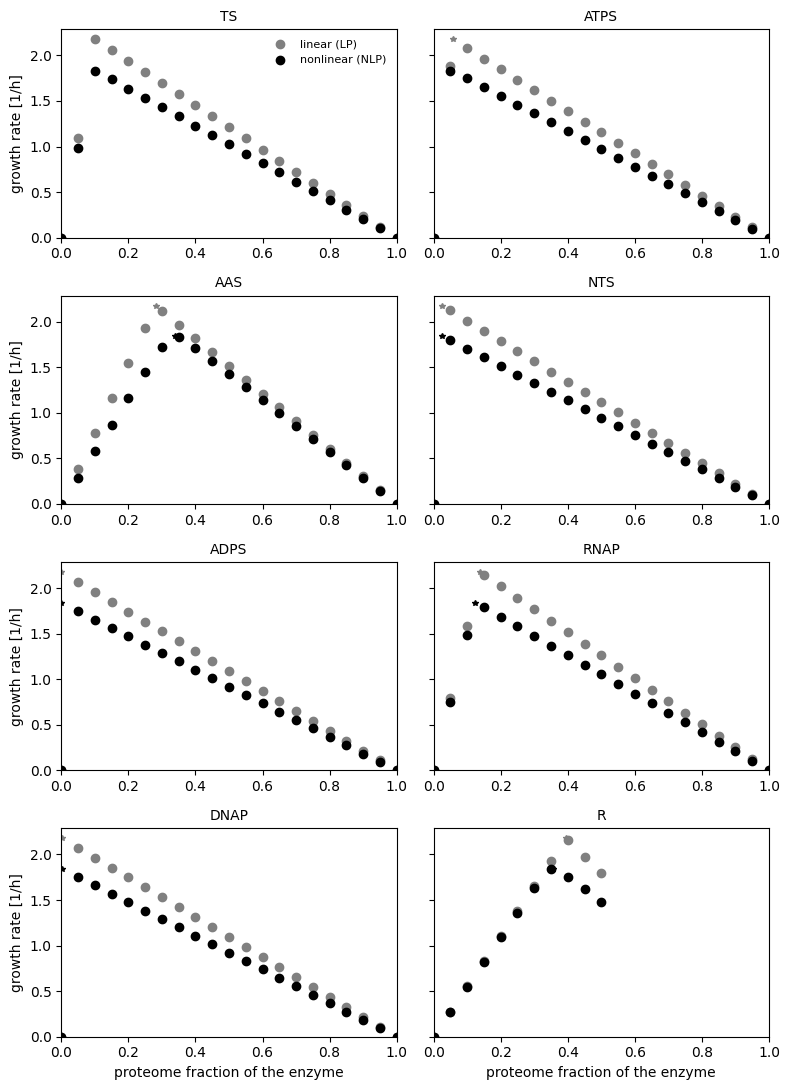

In [17]:
# Proteome fraction of each enzyme at the unperturbed optimum (from sections 6 and 7)
def optimum_phi(result, r):
    return result[f"enzyme_E_{r}_of_{r}"] * ENZ_MW_KDA[r] / model.max_prot_pool

fig, axes = plt.subplots(4, 2, figsize=(8, 11), sharey=True)
for ax, r in zip(axes.flat, stoich):
    phi = np.array(scan[r]["phi"])
    linear = np.array(scan[r]["linear"], dtype=float)
    nonlinear = np.array([np.nan if v is None else v for v in scan[r]["nonlinear"]], dtype=float)
    ax.scatter(phi, linear, color="gray", lw=1, label="linear (LP)")
    ax.scatter(phi, nonlinear, color="black", lw=1, label="nonlinear (NLP)")
    ax.plot(optimum_phi(ec_result, r), ec_result["Biomass"], "*", color="gray", ms=4)
    ax.plot(optimum_phi(nlp_result, r), nlp_result["Biomass"], "*", color="black", ms=4)
    ax.set_title(r, fontsize=10)
    if X_SCALE == "symlog":
        ax.set_xscale("symlog", linthresh=1e-2)
    ax.set_xlim(0, 1)
    ax.set_ylim(bottom=0)
for ax in axes[:, 0]:
    ax.set_ylabel("growth rate [1/h]")
for ax in axes[-1, :]:
    ax.set_xlabel("proteome fraction of the enzyme")
axes[0, 0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIGURE_FILE, dpi=300)
plt.show()

**Reading the curves.** The dots mark the unperturbed optimum of each method. In the runs I did (`CONC_FACTOR` = 1.0001 and 3), the nonlinear curves have the same shape as the linear ones, scaled by the saturation and activation terms (about 0.5 to 0.9). The reason is that metabolite concentrations are free variables inside their bounds and are not linked to the enzyme pool or to the fluxes. For a given reaction, kappa and alpha therefore do not respond to the enzyme levels, and the NLP is an LP with rescaled kcat values. The smooth, nonlinear costs of the GBA figures need a link between concentrations and the pool (the density constraint of GBA). Without dG0 values this model has no such link.

## What differs from the GBA model

Read this before comparing numbers with the manuscript.

* **No density constraint.** In GBA the concentrations follow from mass conservation and the fixed density. Here they are free variables inside their bounds. If `CONC_FACTOR` is large, the NLP pushes substrates to the upper bound and products to the lower bound, and the growth rate moves toward the LP value without kinetics. With `CONC_FACTOR = 1.0001`, concentrations stay at the reference values of the manuscript.
* **Biomass composition is fixed** by the biomass reaction (also the metabolite pools, which dilute by growth). In GBA the composition is a result.
* **Protein pool is a bound.** The modeled proteome of GBA is the product of the ribosome reaction. Here the enzyme pool is limited to the protein fraction of the biomass reaction (0.45 g/gDW), and the ribosome reaction produces protein metabolite P for the biomass reaction. The two are not coupled in COBRAk.
* **Rate law.** COBRAk uses `kappa = exp(sum ln(s/Ks)) / (1 + exp(sum ln(s/Ks)) + exp(sum ln(p/Kp)))`. The convenience kinetics of the manuscript have a different form for several substrates, so kappa differs slightly from the manuscript.
* **No backward kcat.** The backward kcat values (1/5 of the forward values) have no counterpart without dG0, so they are not used.
* **Wext.** The manuscript gives no concentration of the waste product. `A_WEXT` is set to a very low value.